In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [2]:
import seaborn as sns
df = sns.load_dataset("iris")
df.to_csv("iris.csv", index=False)

In [3]:
df .shape

(150, 5)

In [4]:
df.head ()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [5]:
df.sample(3)

,sepal_length,sepal_width,petal_length,petal_width,species
78,6.0,2.9,4.5,1.5,versicolor
21,5.1,3.7,1.5,0.4,setosa
64,5.6,2.9,3.6,1.3,versicolor


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [7]:
df.isnull()

,sepal_length,sepal_width,petal_length,petal_width,species
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
...,...,...,...,...,...
145,False,False,False,False,False
146,False,False,False,False,False
147,False,False,False,False,False
148,False,False,False,False,False


In [8]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [9]:
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
145    False
146    False
147    False
148    False
149    False
Length: 150, dtype: bool

<Axes: xlabel='count', ylabel='species'>

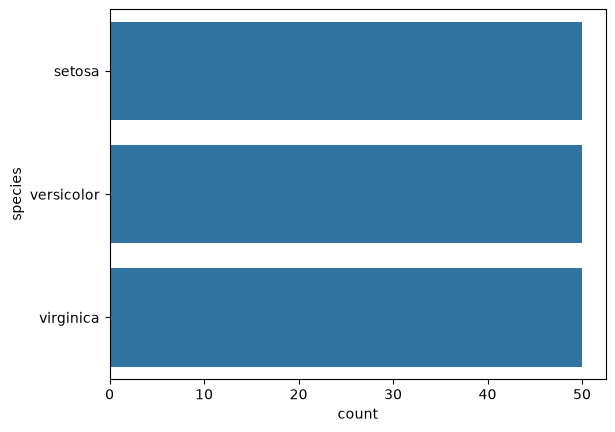

In [14]:
sns.countplot(df['species'])

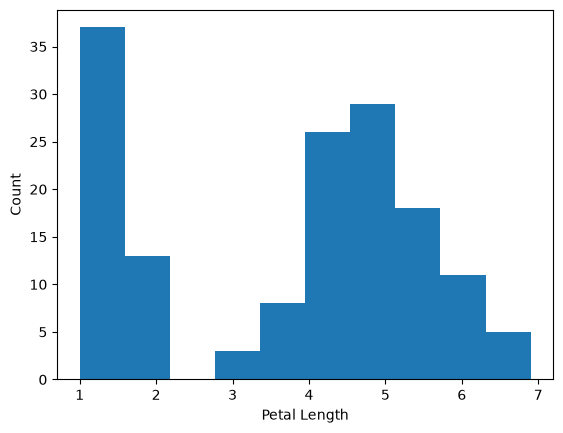

In [18]:
import matplotlib.pyplot as plt

plt.hist(df['petal_length'])
plt.xlabel("Petal Length")
plt.ylabel("Count")
plt.show()

(array([37., 13.,  0.,  3.,  8., 26., 29., 18., 11.,  5.]),
 array([1.  , 1.59, 2.18, 2.77, 3.36, 3.95, 4.54, 5.13, 5.72, 6.31, 6.9 ]),
 <BarContainer object of 10 artists>)

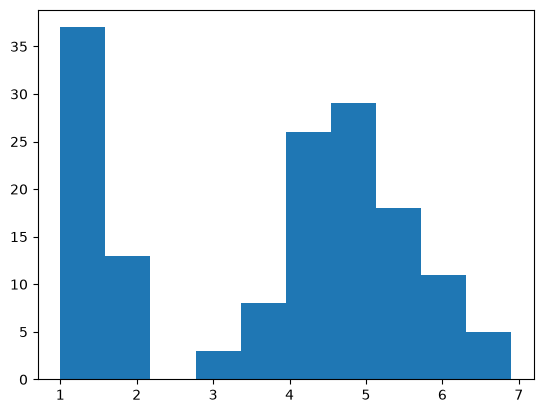

In [19]:
plt.hist([df['petal_length']])

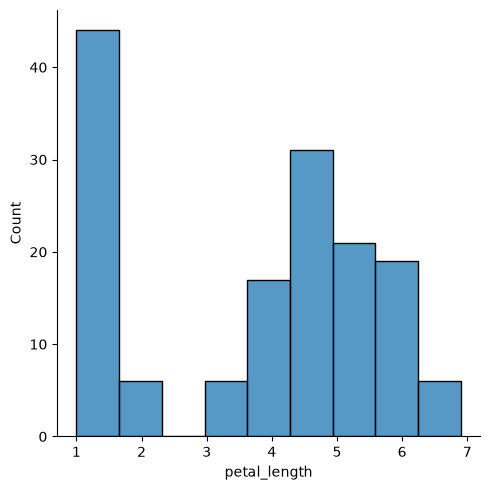

In [20]:
sns.displot(df['petal_length'])

<Axes: xlabel='petal_length'>

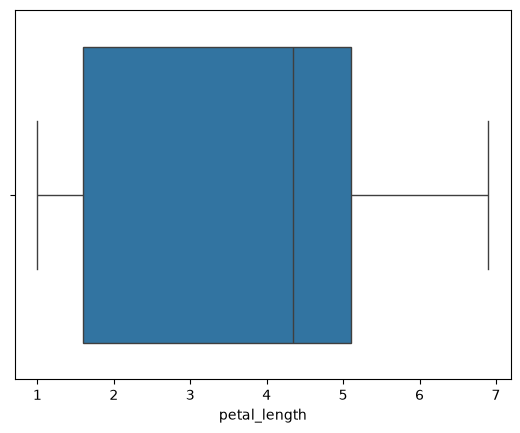

In [21]:
sns.boxplot(x=df['petal_length'])

In [22]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn. preprocessing import StandardScaler

In [23]:
iris = load_iris()

In [24]:
x =iris.data
y = iris .target

In [25]:
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
x_train_s = scaler.fit_transform(x_train)
x_test_s = scaler.transform(x_test)

In [26]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

In [31]:
ls={
    'kNN':KNeighborsClassifier(),
    'LogReg':LogisticRegression(max_iter=200),
    'Tree':DecisionTreeClassifier(random_state=42),
    'SVM':SVC(),
}
for name, m in ls.items():
    m.fit(x_train_s, y_train)

In [32]:
m.score(x_train_s,y_train)

0.975

In [33]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from  sklearn.model_selection import cross_val_score
for name, m in ls.items():
    pred = m.predict(x_test_s)
    print(name, accuracy_score(y_test,pred))

kNN 0.9333333333333333
LogReg 0.9333333333333333
Tree 0.9333333333333333
SVM 0.9666666666666667


In [34]:
confusion_matrix,classification_report
cross_val_score

<function sklearn.model_selection._validation.cross_val_score(estimator, X, y=None, *, groups=None, scoring=None, cv=None, n_jobs=None, verbose=0, params=None, pre_dispatch='2*n_jobs', error_score=nan)>

In [35]:
classification_report

<function sklearn.metrics._classification.classification_report(y_true, y_pred, *, labels=None, target_names=None, sample_weight=None, digits=2, output_dict=False, zero_division='warn')>

In [36]:
for name, m in ls.items():
    pred = m.predict(x_test_s)
    cv = cross_val_score(m, x_train_s, y_train, cv=5)

    print(f"=== {name } | CV Score: {cv.mean():.4f}.===")
    print("confusion_matrix:")
    print(confusion_matrix(y_test, pred))
    print("\nClassification Report:")
    print(classification_report(y_test, pred))

=== kNN | CV Score: 0.9667.===
confusion_matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.83      1.00      0.91        10
           2       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30

=== LogReg | CV Score: 0.9583.===
confusion_matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

=== Tree | CV S

In [37]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.1, 0.01],
    'kernel': ['rbf', 'linear']
}

grid = GridSearchCV(SVC(), param_grid, cv=5)
grid.fit(x_train_s, y_train)

best_model = grid.best_estimator_
print("Best Parameters:", grid.best_params_)
print("Best CV Score:", grid.best_score_)
print("Tuned Test Accuracy:", best_model.score(x_test_s, y_test))

Best Parameters: {'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}
Best CV Score: 0.9833333333333332
Tuned Test Accuracy: 0.9666666666666667


In [38]:
from sklearn.model_selection import GridSearchCV
from  sklearn.svm import SVC
param_grid ={
  'C': [0.1, 1, 10, 100],
    'gamma': ['scale','auto',0.1,0.01],
    'kernel':['rbf', 'linear']
 }
grid = GridSearchCV(SVC(), param_grid, cv=5)
grid.fit(x_train_s, y_train)

best_model = grid.best_estimator_
print("best parameters:", grid.best_params_)
print("best cv score:", grid.best_score_)
print("tuned test accuracy:", best_model.score(x_test_s, y_test))


best parameters: {'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}
best cv score: 0.9833333333333332
tuned test accuracy: 0.9666666666666667


In [39]:
x_train_s = StandardScaler().fit_transform(x_train)

In [41]:
from sklearn.preprocessing import StandardScaler
import numpy as np

scaler = StandardScaler().fit(x_train)

# Example: [sepal_length, sepal_width, petal_length, petal_width]
new_flower = np.array([[5.1, 3.5, 1.4, 0.2]])
new_flower_scaled = scaler.transform(new_flower)

pred = best_model.predict(new_flower_scaled)
species = ['setosa', 'versicolor', 'virginica']

print("Predicted class:", pred[0])
print("Predicted species:", species[pred[0]])

Predicted class: 0
Predicted species: setosa


In [42]:
import joblib

joblib.dump(best_model, 'iris_svm_model.pkl')
joblib.dump(scaler, 'iris_scaler.pkl')
print("Model aur scaler save ho gaye!")

Model aur scaler save ho gaye!


In [47]:
import joblib
import numpy as np
import streamlit as st

st.title("Iris Flower Classifier")
st.write("Sepal aur petal ki values enter karein aur flower ki species jaanein:")

sepal_length = st.number_input("Sepal Length (cm)", min_value=0.0, max_value=10.0, value=5.1)
sepal_width = st.number_input("Sepal Width (cm)", min_value=0.0, max_value=10.0, value=3.5)
petal_length = st.number_input("Petal Length (cm)", min_value=0.0, max_value=10.0, value=1.4)
petal_width = st.number_input("Petal Width (cm)", min_value=0.0, max_value=10.0, value=0.2)

if st.button("Predict"):
    model = joblib.load("iris_svm_model.pkl")
    scaler = joblib.load("iris_scaler.pkl")

    sample = np.array([[sepal_length, sepal_width, petal_length, petal_width]])
    sample_scaled = scaler.transform(sample)
    pred = model.predict(sample_scaled)[0]

    species = ["Setosa", "Versicolor", "Virginica"]
    st.success(f"Predicted Species: **{species[pred]}**")

2026-11-26 04:52:29.256 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 04:52:29.755 
  command:

    streamlit run C:\Users\GC ANEEQ\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-11-26 04:52:29.755 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 04:52:29.755 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 04:52:29.755 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 04:52:29.755 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-26 04:52:29.755 Thread 'MainThread': missing ScriptRunContext! Thi

In [46]:
pip install streamlit


Defaulting to user installation because normal site-packages is not writeable
  Using cached altair-6.3.0-py3-none-any.whl.metadata (11 kB)
  Using cached pydeck-0.9.3-py2.py3-none-any.whl.metadata (4.2 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   -------------------


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\GC ANEEQ\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
  Using cached streamlit-1.67.0-py3-none-any.whl.metadata (10 kB)
  Using cached altair-6.3.0-py3-none-any.whl.metadata (11 kB)
  Using cached click-8.5.1-py3-none-any.whl.metadata (2.6 kB)
  Using cached pydeck-0.9.3-py2.py3-none-any.whl.metadata (4.2 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached pyarrow-26.0.1-cp312-cp312-win_amd64.whl.metadata (3.0 kB)
  Using cached starlette-1.10.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached python_multipart-0.0.34-py3-none-any.whl.metadata (6.3 kB)
  Using cached websockets-17.4-cp312-cp312-win_amd64.whl.metadata (6.5 kB)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
  Using cached watchdog-7.1.1-py3-none-win_amd64.whl.metadata (69 kB)
Using cached streamlit-1.67.0-py3-none-any.whl (11.2 MB)
Using cached altair-6.3.0-py3-none-an


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\GC ANEEQ\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip
ERROR: Exception:
Traceback (most recent call last):
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.12_3.12.2800.0_x64__qbz5n2kfra8p0\Lib\site-packages\pip\_vendor\urllib3\response.py", line 438, in _error_catcher
    yield
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.12_3.12.2800.0_x64__qbz5n2kfra8p0\Lib\site-packages\pip\_vendor\urllib3\response.py", line 561, in read
    data = self._fp_read(amt) if not fp_closed else b""
           ^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.12_3.12.2800.0_x64__qbz5n2kfra8p0\Lib\site-packages\pip\_vendor\urllib3\response.py", line 527, in _fp_read
    return self._fp.read(amt) if amt is not None else self._fp.read()
           ^

In [49]:
streamlit run "D:\screen shot\ml .npy.ipynb"

SyntaxError: invalid syntax (3362596755.py, line 1)